In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("seeds_data.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())


Dataset shape: (210, 8)

First five rows:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Column names:
['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Class']

Missing values:
Feature_1    0
Feature_2    0
Feature_3    0
Feature_4    0
Feature_5    0
Feature_6    0
Feature_7    0
Class        0
dtype: int64

Class distribution:
Class
1    70
2    70
3    70
Name: count, dtype: int64


In [4]:

# Separate features from the true labels
X = df.drop(columns=["Class"]).to_numpy(dtype=float)
y_true = df["Class"].to_numpy()

print("Feature matrix shape:", X.shape)
print("True labels shape:", y_true.shape)
print("Unique true classes:", np.unique(y_true))


Feature matrix shape: (210, 7)
True labels shape: (210,)
Unique true classes: [1 2 3]


In [5]:

# Calculate mean and standard deviation for each feature
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)

# Prevent division by zero if any feature has zero variance
X_std[X_std == 0] = 1

# Standardize the data
X_scaled = (X - X_mean) / X_std

print("Standardized feature means:")
print(np.round(np.mean(X_scaled, axis=0), 4))

print("\nStandardized feature standard deviations:")
print(np.round(np.std(X_scaled, axis=0), 4))

print("\nStandardized data shape:", X_scaled.shape)


Standardized feature means:
[-0.  0.  0. -0. -0. -0. -0.]

Standardized feature standard deviations:
[1. 1. 1. 1. 1. 1. 1.]

Standardized data shape: (210, 7)


In [6]:

def kmeans(X, k, max_iters=300, tol=1e-4, random_state=42):
    rng = np.random.default_rng(random_state)

    # Randomly select k distinct data points as initial centers
    centers = X[rng.choice(len(X), size=k, replace=False)].copy()

    for iteration in range(max_iters):
        # Calculate Euclidean distances from every point to every center
        distances = np.sqrt(
            np.sum((X[:, np.newaxis, :] - centers[np.newaxis, :, :]) ** 2,
                   axis=2)
        )

        # Assign each point to its nearest center
        labels = np.argmin(distances, axis=1)

        # Calculate new centers
        new_centers = centers.copy()

        for cluster in range(k):
            points = X[labels == cluster]

            if len(points) > 0:
                new_centers[cluster] = np.mean(points, axis=0)
            else:
                # Reinitialize an empty cluster to a random data point
                new_centers[cluster] = X[rng.integers(len(X))]

        # Stop if the centers have barely moved
        movement = np.linalg.norm(new_centers - centers)
        centers = new_centers

        if movement < tol:
            break

    # Recalculate final assignments using the final centers
    distances = np.sqrt(
        np.sum((X[:, np.newaxis, :] - centers[np.newaxis, :, :]) ** 2,
               axis=2)
    )
    labels = np.argmin(distances, axis=1)

    return labels, centers


In [7]:

def calculate_wcss(X, labels, centers):
    wcss = 0.0

    for cluster in range(len(centers)):
        points = X[labels == cluster]

        if len(points) > 0:
            wcss += np.sum((points - centers[cluster]) ** 2)

    return wcss


# Test different numbers of clusters
k_values = range(1, 11)
wcss_values = []

for k in k_values:
    labels, centers = kmeans(X_scaled, k)
    wcss = calculate_wcss(X_scaled, labels, centers)
    wcss_values.append(wcss)

    print(f"K = {k}, WCSS = {wcss:.2f}")


K = 1, WCSS = 1470.00
K = 2, WCSS = 659.94
K = 3, WCSS = 430.82
K = 4, WCSS = 372.89
K = 5, WCSS = 350.92
K = 6, WCSS = 303.40
K = 7, WCSS = 278.67
K = 8, WCSS = 240.25
K = 9, WCSS = 241.12
K = 10, WCSS = 223.54


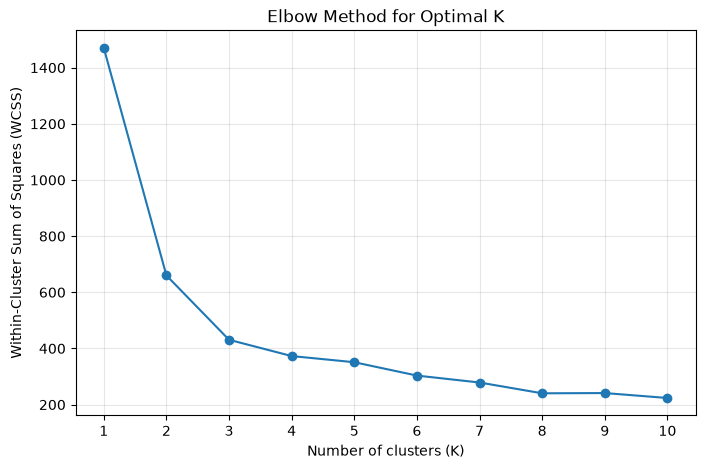

In [8]:

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()


In [9]:

# Fit K-Means with the selected number of clusters
optimal_k = 3

kmeans_labels, kmeans_centers = kmeans(X_scaled, optimal_k)

print("Number of clusters:", optimal_k)
print("\nFinal cluster centers (standardized feature space):")

for i, center in enumerate(kmeans_centers):
    print(f"\nCluster {i}:")
    print(np.round(center, 4))

print("\nNumber of seeds in each cluster:")
for cluster in range(optimal_k):
    print(f"Cluster {cluster}: {np.sum(kmeans_labels == cluster)} seeds")


Number of clusters: 3

Final cluster centers (standardized feature space):

Cluster 0:
[ 1.2265  1.2357  0.5327  1.2199  1.1304 -0.0468  1.2802]

Cluster 1:
[-0.1671 -0.2038  0.4752 -0.3027 -0.012  -0.6822 -0.6398]

Cluster 2:
[-1.0272 -1.     -0.9863 -0.8872 -1.0867  0.718  -0.6134]

Number of seeds in each cluster:
Cluster 0: 69 seeds
Cluster 1: 70 seeds
Cluster 2: 71 seeds


In [10]:

def pairwise_distances(X):
    # Distance between every pair of points
    differences = X[:, np.newaxis, :] - X[np.newaxis, :, :]
    distances = np.sqrt(np.sum(differences ** 2, axis=2))
    return distances


distance_matrix = pairwise_distances(X_scaled)

print("Distance matrix shape:", distance_matrix.shape)
print("Distance between the first two seeds:",
      round(distance_matrix[0, 1], 4))


Distance matrix shape: (210, 210)
Distance between the first two seeds: 1.1847


In [11]:

def dbscan(distance_matrix, eps, min_samples):
    n = distance_matrix.shape[0]

    # Initially, all points are unvisited
    UNVISITED = -2
    NOISE = -1

    labels = np.full(n, UNVISITED, dtype=int)
    cluster_id = 0

    # Find all points within eps distance of a given point
    def region_query(point_idx):
        return np.where(distance_matrix[point_idx] <= eps)[0]

    for point_idx in range(n):
        # Skip points already processed
        if labels[point_idx] != UNVISITED:
            continue

        neighbors = region_query(point_idx)

        # If too few neighbors, mark as noise for now
        if len(neighbors) < min_samples:
            labels[point_idx] = NOISE
            continue

        # Otherwise, start a new cluster
        labels[point_idx] = cluster_id

        # Expand the cluster using the neighbors
        seeds = list(neighbors)
        seed_set = set(seeds)
        i = 0

        while i < len(seeds):
            current_point = seeds[i]

            # A previously marked noise point may belong to this cluster
            if labels[current_point] == NOISE:
                labels[current_point] = cluster_id

            # Already assigned to a cluster; don't process again
            if labels[current_point] != UNVISITED:
                i += 1
                continue

            labels[current_point] = cluster_id
            current_neighbors = region_query(current_point)

            # Only core points can expand the cluster
            if len(current_neighbors) >= min_samples:
                for neighbor in current_neighbors:
                    if neighbor not in seed_set:
                        seeds.append(neighbor)
                        seed_set.add(neighbor)

            i += 1

        cluster_id += 1

    return labels


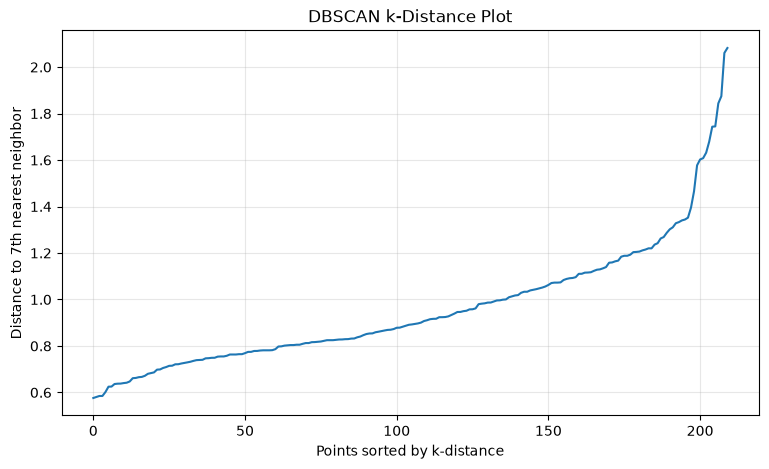

In [12]:

min_samples_choice = 7

# Sort each row's distances from smallest to largest.
# The first distance is zero because each point is its own neighbor.
sorted_distances = np.sort(distance_matrix, axis=1)

# Index 6 corresponds to the 7th nearest neighbor, including the point itself.
k_distances = sorted_distances[:, min_samples_choice - 1]

# Sort these distances across all points
k_distances_sorted = np.sort(k_distances)

plt.figure(figsize=(9, 5))
plt.plot(range(len(k_distances_sorted)), k_distances_sorted)
plt.xlabel("Points sorted by k-distance")
plt.ylabel(f"Distance to {min_samples_choice}th nearest neighbor")
plt.title("DBSCAN k-Distance Plot")
plt.grid(True, alpha=0.3)
plt.show()


In [13]:

eps_values = [0.9, 1.0, 1.1, 1.2, 1.3, 1.4]
min_samples_values = [5, 7, 10]

results = []

for min_s in min_samples_values:
    for eps_value in eps_values:
        labels = dbscan(distance_matrix, eps_value, min_s)

        # Noise points have label -1
        noise_count = np.sum(labels == -1)

        # Exclude noise when counting clusters
        n_clusters = len(set(labels) - {-1})

        results.append({
            "eps": eps_value,
            "min_samples": min_s,
            "clusters": n_clusters,
            "noise_points": noise_count
        })

results_df = pd.DataFrame(results)
display(results_df)


,eps,min_samples,clusters,noise_points
0,0.9,5,1,28
1,1.0,5,1,13
2,1.1,5,1,9
3,1.2,5,1,6
4,1.3,5,1,4
5,1.4,5,1,3
6,0.9,7,2,52
7,1.0,7,2,25
8,1.1,7,1,16
9,1.2,7,1,7


In [14]:

eps_values_fine = [0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
min_samples_values_fine = [5, 7, 10]

fine_results = []

for min_s in min_samples_values_fine:
    for eps_value in eps_values_fine:
        labels = dbscan(distance_matrix, eps_value, min_s)

        fine_results.append({
            "eps": eps_value,
            "min_samples": min_s,
            "clusters": len(set(labels) - {-1}),
            "noise_points": np.sum(labels == -1)
        })

fine_results_df = pd.DataFrame(fine_results)
display(fine_results_df)


,eps,min_samples,clusters,noise_points
0,0.65,5,7,110
1,0.70,5,7,78
2,0.75,5,5,66
3,0.80,5,3,59
4,0.85,5,2,47
5,0.90,5,1,28
6,0.65,7,4,158
7,0.70,7,5,128
8,0.75,7,4,103
9,0.80,7,4,87


In [15]:

# Selected DBSCAN parameters
best_eps = 0.80
best_min_samples = 5

dbscan_labels = dbscan(
    distance_matrix,
    eps=best_eps,
    min_samples=best_min_samples
)

# Count clusters and noise points
dbscan_clusters = sorted(set(dbscan_labels) - {-1})
n_dbscan_clusters = len(dbscan_clusters)
n_noise = np.sum(dbscan_labels == -1)

print("DBSCAN Results")
print("-------------------------")
print("Epsilon (eps):", best_eps)
print("Minimum samples:", best_min_samples)
print("Number of clusters formed:", n_dbscan_clusters)
print("Total noise/outlier points:", n_noise)
print("Points assigned to clusters:", np.sum(dbscan_labels != -1))

print("\nCluster sizes:")
for cluster in dbscan_clusters:
    print(f"Cluster {cluster}: {np.sum(dbscan_labels == cluster)} seeds")


DBSCAN Results
-------------------------
Epsilon (eps): 0.8
Minimum samples: 5
Number of clusters formed: 3
Total noise/outlier points: 59
Points assigned to clusters: 151

Cluster sizes:
Cluster 0: 107 seeds
Cluster 1: 15 seeds
Cluster 2: 29 seeds


In [16]:

def pca_from_scratch(X, n_components=2):
    # Center the data
    X_centered = X - np.mean(X, axis=0)

    # Compute the covariance matrix
    covariance_matrix = np.cov(X_centered, rowvar=False)

    # Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

    # Sort components by descending eigenvalue
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]

    # Select the top principal components
    components = eigenvectors[:, :n_components]

    # Project the data into the reduced space
    X_reduced = X_centered @ components

    # Calculate explained variance ratio
    explained_variance_ratio = (
        eigenvalues[:n_components] / np.sum(eigenvalues)
    )

    return X_reduced, components, explained_variance_ratio


X_pca, pca_components, explained_variance = pca_from_scratch(
    X_scaled, n_components=2
)

print("Original dimensions:", X_scaled.shape[1])
print("Reduced dimensions:", X_pca.shape[1])
print("Explained variance ratio:", np.round(explained_variance, 4))
print(
    "Total variance retained:",
    f"{np.sum(explained_variance) * 100:.2f}%"
)


Original dimensions: 7
Reduced dimensions: 2
Explained variance ratio: [0.7187 0.1711]
Total variance retained: 88.98%


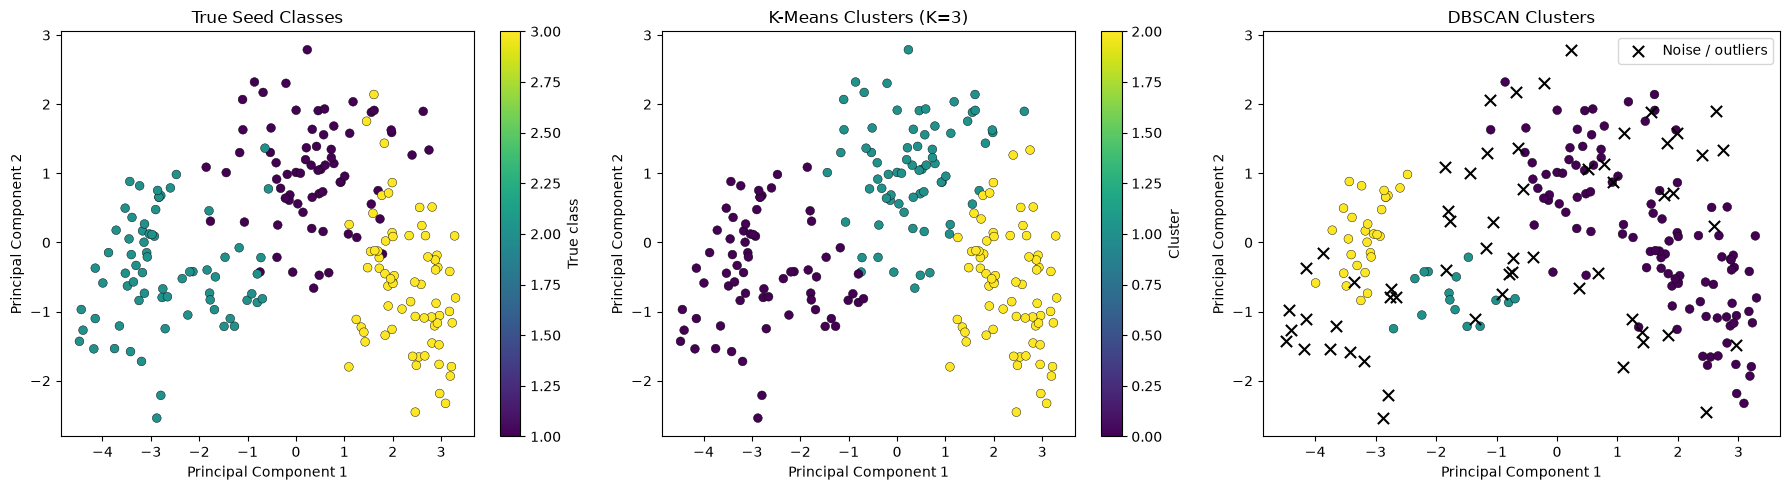

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. True labels (used only for comparison)
scatter1 = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_true, cmap="viridis", s=40, edgecolors="k", linewidths=0.3
)
axes[0].set_title("True Seed Classes")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
fig.colorbar(scatter1, ax=axes[0], label="True class")

# 2. K-Means clusters
scatter2 = axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_labels, cmap="viridis", s=40, edgecolors="k", linewidths=0.3
)
axes[1].set_title("K-Means Clusters (K=3)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
fig.colorbar(scatter2, ax=axes[1], label="Cluster")

# 3. DBSCAN clusters, with noise highlighted
noise_mask = dbscan_labels == -1
cluster_mask = ~noise_mask

scatter3 = axes[2].scatter(
    X_pca[cluster_mask, 0], X_pca[cluster_mask, 1],
    c=dbscan_labels[cluster_mask],
    cmap="viridis", s=40, edgecolors="k", linewidths=0.3
)

axes[2].scatter(
    X_pca[noise_mask, 0], X_pca[noise_mask, 1],
    c="black", marker="x", s=65, label="Noise / outliers"
)
axes[2].set_title("DBSCAN Clusters")
axes[2].set_xlabel("Principal Component 1")
axes[2].set_ylabel("Principal Component 2")
axes[2].legend()

plt.tight_layout()
plt.show()


In [18]:

# Compare actual classes with the predicted cluster assignments
print("K-Means: True Class vs Predicted Cluster")
display(pd.crosstab(
    pd.Series(y_true, name="True Class"),
    pd.Series(kmeans_labels, name="K-Means Cluster")
))

print("\nDBSCAN: True Class vs Predicted Cluster")
display(pd.crosstab(
    pd.Series(y_true, name="True Class"),
    pd.Series(dbscan_labels, name="DBSCAN Cluster")
))


K-Means: True Class vs Predicted Cluster


K-Means Cluster,0,1,2
True Class,,,
1,2,63,5
2,67,3,0
3,0,4,66



DBSCAN: True Class vs Predicted Cluster


DBSCAN Cluster,-1,0,1,2
True Class,,,,
1,22,48,0,0
2,26,0,15,29
3,11,59,0,0


In [19]:
    
from math import comb, log

def clustering_metrics(y_true, y_pred):
    # Map arbitrary class and cluster labels to integer indices
    _, true_encoded = np.unique(y_true, return_inverse=True)
    _, pred_encoded = np.unique(y_pred, return_inverse=True)

    n = len(y_true)
    n_true = true_encoded.max() + 1
    n_pred = pred_encoded.max() + 1

    # Build the contingency matrix
    contingency = np.zeros((n_true, n_pred), dtype=int)

    for i in range(n):
        contingency[true_encoded[i], pred_encoded[i]] += 1

    # ARI: pair-counting formula
    sum_cells = sum(comb(int(v), 2) for v in contingency.ravel())
    row_sums = contingency.sum(axis=1)
    col_sums = contingency.sum(axis=0)

    sum_rows = sum(comb(int(v), 2) for v in row_sums)
    sum_cols = sum(comb(int(v), 2) for v in col_sums)
    total_pairs = comb(n, 2)

    expected_index = (sum_rows * sum_cols) / total_pairs
    max_index = (sum_rows + sum_cols) / 2

    denominator = max_index - expected_index
    ari = (
        (sum_cells - expected_index) / denominator
        if denominator != 0 else 1.0
    )

    # NMI: mutual information divided by geometric mean of entropies
    probabilities = contingency / n
    true_probs = row_sums / n
    pred_probs = col_sums / n

    mutual_information = 0.0

    for i in range(n_true):
        for j in range(n_pred):
            p = probabilities[i, j]

            if p > 0:
                mutual_information += p * log(
                    p / (true_probs[i] * pred_probs[j])
                )

    true_entropy = -sum(
        p * log(p) for p in true_probs if p > 0
    )
    pred_entropy = -sum(
        p * log(p) for p in pred_probs if p > 0
    )

    entropy_product = true_entropy * pred_entropy
    nmi = (
        mutual_information / np.sqrt(entropy_product)
        if entropy_product > 0 else 1.0
    )

    return ari, nmi


# Evaluate K-Means
kmeans_ari, kmeans_nmi = clustering_metrics(y_true, kmeans_labels)

# Evaluate DBSCAN, treating noise (-1) as its own label
dbscan_ari, dbscan_nmi = clustering_metrics(y_true, dbscan_labels)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "ARI": [kmeans_ari, dbscan_ari],
    "NMI": [kmeans_nmi, dbscan_nmi]
})

print("Clustering Evaluation")
display(comparison.round(4))


Clustering Evaluation


,Algorithm,ARI,NMI
0,K-Means,0.8112,0.763
1,DBSCAN,0.2730,0.403


In [20]:

assigned_mask = dbscan_labels != -1

if np.any(assigned_mask):
    assigned_ari, assigned_nmi = clustering_metrics(
        y_true[assigned_mask],
        dbscan_labels[assigned_mask]
    )

    print("DBSCAN evaluation on assigned points only")
    print("Points evaluated:", np.sum(assigned_mask))
    print("Points excluded as noise:", np.sum(~assigned_mask))
    print(f"ARI: {assigned_ari:.4f}")
    print(f"NMI: {assigned_nmi:.4f}")
else:
    print("DBSCAN did not assign any points to clusters.")


DBSCAN evaluation on assigned points only
Points evaluated: 151
Points excluded as noise: 59
ARI: 0.4401
NMI: 0.6498


In [21]:

print("=" * 60)
print("TASK 2.2 - CLUSTERING: FINAL SUMMARY")
print("=" * 60)

print("\n1. DATASET")
print(f"Number of seed samples: {len(X)}")
print(f"Number of input features: {X.shape[1]}")
print("Target labels excluded during clustering: Yes")

print("\n2. K-MEANS")
print(f"Number of clusters: {optimal_k}")
print(f"Cluster sizes: {np.bincount(kmeans_labels).tolist()}")
print(f"ARI: {kmeans_ari:.4f}")
print(f"NMI: {kmeans_nmi:.4f}")
print("Final cluster centers:")
print(np.round(kmeans_centers, 4))

print("\n3. DBSCAN")
print(f"Epsilon (eps): {best_eps}")
print(f"Minimum samples: {best_min_samples}")
print(f"Clusters formed: {n_dbscan_clusters}")
print(f"Noise points: {n_noise}")
print(f"ARI: {dbscan_ari:.4f}")
print(f"NMI: {dbscan_nmi:.4f}")

print("\n4. PCA")
print(f"Components retained: {X_pca.shape[1]}")
print(f"Variance retained: {np.sum(explained_variance) * 100:.2f}%")

print("\n5. CONCLUSION")
print("K-Means achieved stronger overall agreement with the true")
print("seed classes than DBSCAN under the tested configurations.")
print("DBSCAN identified noise points but did not separate all")
print("three seed classes effectively with the selected parameters.")
print("=" * 60)


TASK 2.2 - CLUSTERING: FINAL SUMMARY

1. DATASET
Number of seed samples: 210
Number of input features: 7
Target labels excluded during clustering: Yes

2. K-MEANS
Number of clusters: 3
Cluster sizes: [69, 70, 71]
ARI: 0.8112
NMI: 0.7630
Final cluster centers:
[[ 1.2265  1.2357  0.5327  1.2199  1.1304 -0.0468  1.2802]
 [-0.1671 -0.2038  0.4752 -0.3027 -0.012  -0.6822 -0.6398]
 [-1.0272 -1.     -0.9863 -0.8872 -1.0867  0.718  -0.6134]]

3. DBSCAN
Epsilon (eps): 0.8
Minimum samples: 5
Clusters formed: 3
Noise points: 59
ARI: 0.2730
NMI: 0.4030

4. PCA
Components retained: 2
Variance retained: 88.98%

5. CONCLUSION
K-Means achieved stronger overall agreement with the true
seed classes than DBSCAN under the tested configurations.
DBSCAN identified noise points but did not separate all
three seed classes effectively with the selected parameters.


## Conclusion

In this task, K-Means and DBSCAN clustering algorithms were implemented from scratch using NumPy. The target labels were excluded from model training and used only for post-clustering evaluation and visualization.

The Elbow Method suggested three clusters for K-Means. The model formed three relatively balanced clusters containing 69, 70, and 71 samples. It achieved an Adjusted Rand Index (ARI) of 0.8112 and a Normalized Mutual Information (NMI) score of 0.7630, indicating strong agreement with the actual seed categories.

DBSCAN was implemented using Euclidean distances on standardized features. A k-distance plot and parameter experiments were used to select `eps = 0.80` and `min_samples = 5`. This configuration produced three clusters but classified 59 of the 210 samples as noise. Its overall ARI was 0.2730 and NMI was 0.4030.

Principal Component Analysis (PCA) was also implemented from scratch to project the seven-dimensional feature space into two dimensions. The first two principal components retained 88.98% of the total variance, allowing visual comparison of the true classes and predicted clusters.

Overall, K-Means performed better than DBSCAN under the configurations tested. This illustrates that K-Means can be effective when the data has relatively well-separated groups, while DBSCAN's performance depends strongly on neighborhood density and parameter selection. The results do not establish that K-Means is universally superior; other DBSCAN parameters or distance metrics may produce different outcomes.